# 01 - Data Inspection & EDA

Purpose: Review the downloaded dataset to view an initial shape of datasets, uncover data quality issues like weird patterns, missing data , category inspection etc.

### 01 - Notebook Setup

In [36]:
# ---------- Cell 1: imports and load ----------
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS


df = pd.read_csv("../data/support_tickets_en.csv")

### 02 - Basic Inspection

In [37]:
# ---------- Cell 2: basic inspection ----------
print("Shape:", df.shape)
print("\nData types:")
display(df.dtypes.to_frame(name="Data Type"))

print("\nMissing values:")
display(df.isna().sum().to_frame(name="Missing"))

# Duplicates: exact rows, same subject+body, and repeated subjects
print("\nExact duplicate rows:", df.duplicated().sum())
print("Duplicate subject+body:", df.duplicated(subset=["subject", "body"]).sum())
print("Repeated subjects:", df["subject"].duplicated().sum())

df.head(3)
# Finding to note: how many missing values and duplicates there are,
# and which columns they are in (decide later whether to drop them)

Shape: (28261, 5)

Data types:


,Data Type
subject,str
body,str
answer,str
queue,str
priority,str



Missing values:


,Missing
subject,3639
body,1
answer,6
queue,0
priority,0



Exact duplicate rows: 4460
Duplicate subject+body: 4513
Repeated subjects: 9196


,subject,body,answer,queue,priority
0,Account Disruption,"Dear Customer Support Team,\n\nI am writing to...","Thank you for reaching out, <name>. We are awa...",Technical Support,high
1,Query About Smart Home System Integration Feat...,"Dear Customer Support Team,\n\nI hope this mes...",Thank you for your inquiry. Our products suppo...,Returns and Exchanges,medium
2,Inquiry Regarding Invoice Details,"Dear Customer Support Team,\n\nI hope this mes...",We appreciate you reaching out with your billi...,Billing and Payments,low


#### Insights:
- 28,261 rows and 5 columns. Missing values: subject 3,639 (13%), body 1, answer 6.
- 4,460 exact duplicate rows and 4,513 duplicates on subject+body. The extra 53 rows share the same text but differ in answer, queue or priority, which is worth checking as possible label conflict.
- "Repeated subjects" (9,196) is inflated by the missing subjects and by generic subject lines, so it is not acted on.
- Duplicates must be dropped before the train/test split.

### 03 - Feature Creation:

In [38]:
# ---------- Cell 3: build one text field and fix the "\n" problem ----------
# Check: do bodies contain the two characters backslash + n (not real line breaks)?
print("Bodies with literal \\n:", df["body"].str.contains("\\n", regex=False).sum())

# Combine subject + body, replace both literal and real newlines with a space, lowercase
df["text"] = df["subject"].fillna("") + " " + df["body"].fillna("")
df["text"] = (
    df["text"]
    .str.replace("\\n", " ", regex=False)   # literal backslash-n
    .str.replace("\n", " ", regex=False)    # real line breaks
    .str.lower()
)
df["text"].iloc[0]

Bodies with literal \n: 997


'account disruption dear customer support team,  i am writing to report a significant problem with the centralized account management portal, which currently appears to be offline. this outage is blocking access to account settings, leading to substantial inconvenience. i have attempted to log in multiple times using different browsers and devices, but the issue persists.  could you please provide an update on the outage status and an estimated time for resolution? also, are there any alternative ways to access and manage my account during this downtime?'

#### Insights:
- 997 bodies contain a literal backslash + n (not a real line break). Both kinds of newline are replaced with a space before cleaning.
- Subject and body are joined into one text field. About 13% of tickets have no subject, so the subject is treated as empty text and the row is kept.

### 04 - Text Length:

       char_count  word_count
count     28261.0     28261.0
mean        410.1        60.5
std         203.2        31.5
min           5.0         1.0
25%         245.0        35.0
50%         404.0        59.0
75%         568.0        84.0
max        1805.0       288.0

Tickets under 10 words: 320

Average words by priority:
 priority
high      60.0
low       60.7
medium    60.8
Name: word_count, dtype: float64


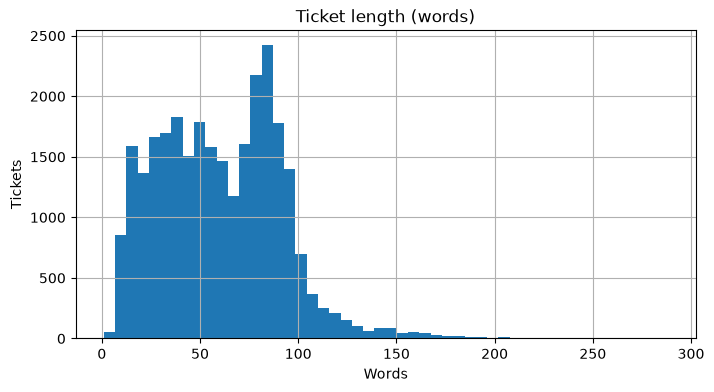

In [39]:
# ---------- Cell 4: text length ----------
df["char_count"] = df["text"].str.len()
df["word_count"] = df["text"].str.split().str.len()

print(df[["char_count", "word_count"]].describe().round(1))
print("\nTickets under 10 words:", (df["word_count"] < 10).sum())
print("\nAverage words by priority:\n", df.groupby("priority")["word_count"].mean().round(1))

df["word_count"].hist(bins=50, figsize=(8, 4))
plt.title("Ticket length (words)")
plt.xlabel("Words")
plt.ylabel("Tickets")
plt.show()
# Finding to note: typical length, any extreme tickets, whether priority affects length

#### Insights:
- Typical ticket is about 60 words (median 59, max 288). 320 tickets have under 10 words and should be inspected before deciding whether to drop the extremely short ones.
- Average length is almost identical across priorities (high 60.0, low 60.7, medium 60.8), so length is **not** a useful feature. Metadata features are skipped.

### 05 - Class Ditribution:

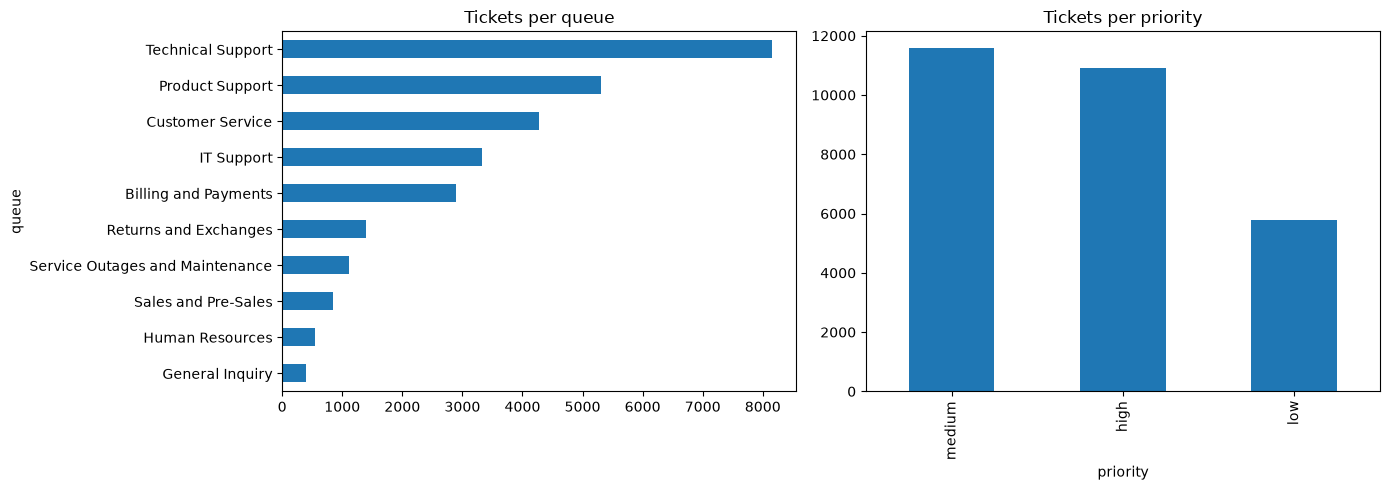

queue
Technical Support                  0.288
Product Support                    0.188
Customer Service                   0.151
IT Support                         0.118
Billing and Payments               0.103
Returns and Exchanges              0.050
Service Outages and Maintenance    0.039
Sales and Pre-Sales                0.030
Human Resources                    0.020
General Inquiry                    0.014
Name: proportion, dtype: float64
priority
medium    0.409
high      0.386
low       0.204
Name: proportion, dtype: float64


In [40]:
# ---------- Cell 5: class distributions ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
df["queue"].value_counts().sort_values().plot(kind="barh", ax=axes[0], title="Tickets per queue")
df["priority"].value_counts().plot(kind="bar", ax=axes[1], title="Tickets per priority")
plt.tight_layout()
plt.show()

print(df["queue"].value_counts(normalize=True).round(3))
print(df["priority"].value_counts(normalize=True).round(3))

#### Insights:
- Queue is imbalanced: Technical Support is 28.8% of tickets and General Inquiry only 1.4%. The top 5 queues cover 84.8%.
- Priority is moderately imbalanced: medium 40.9%, high 38.6%, low 20.4%. Majority-class accuracy (always predicting medium) is about 41%, which is the reference baseline for the priority model.
- Because of the imbalance, models are compared on macro F1 and `class_weight='balanced'` is used for the baseline.

### 06: does priority depend on queue?

In [41]:
# ---------- Cell 6: does priority depend on queue? ----------
# Each row sums to 1: share of low/medium/high tickets inside each queue
print(pd.crosstab(df["queue"], df["priority"], normalize="index").round(2))
# Finding to note: if every queue has a similar priority mix, queue tells us
# little about priority, so priority must come from the text itself

priority                         high   low  medium
queue                                              
Billing and Payments             0.29  0.21    0.50
Customer Service                 0.18  0.33    0.49
General Inquiry                  0.16  0.59    0.25
Human Resources                  0.10  0.48    0.42
IT Support                       0.47  0.10    0.43
Product Support                  0.30  0.19    0.51
Returns and Exchanges            0.22  0.37    0.41
Sales and Pre-Sales              0.18  0.36    0.46
Service Outages and Maintenance  0.70  0.13    0.17
Technical Support                0.58  0.12    0.30


#### Insights:
- Priority is not independent of queue. Service Outages is 70% high, Technical Support 58% high, IT Support 47% high, and General Inquiry 59% low.
- So topic gives some priority signal, but every queue still contains a mix of priorities, which limits how well priority can be predicted.
- Service Outages is outside the top 5 queues, so the priority model should be trained on all queues (otherwise it never sees the most urgent tickets). The true queue must never be an input to the priority model, since it is not known at prediction time.

### 07: read random tickets to judge label quality

In [42]:
# ---------- Cell 7: read random tickets to judge label quality ----------
sample = df.sample(20, random_state=42)

for _, row in sample.iterrows():
    print(f"[{row['queue']} | {row['priority']}]")
    print("   ", row["text"][:250], "\n")
# Finding to note: how many of these 20 look misrouted or oddly prioritized
# (write the count down, it becomes your label-noise estimate)

[Product Support | low]
     please request an update to the integration settings to ensure compatibility with various devices for the software project management workflows, to guarantee seamless operations. 

[Technical Support | high]
    data breach happened because of lack of encryption insufficient encryption led to the data breach problem 

[Customer Service | low]
    query concerning decline in website traffic the analytics data for the website have indicated a notable decrease in traffic last week. this could be due to recent algorithm changes or technical issues. despite efforts to update seo strategies and opt 

[Technical Support | medium]
     i am currently encountering integration problems with cyberlink powerdirector 19, davinci resolve 17, and asana following the recent update. 

[Customer Service | high]
    optimization of investments using alteryx hello customer support, i am interested in understanding how alteryx can improve our data analytics for investment optim

#### Insights:
- Reading 20 random tickets, about 4 had a clearly wrong queue (for example an investment-analytics inquiry routed to Returns and Exchanges, or encryption of medical data routed to Billing). About 5 more were ambiguous, and a few priorities looked odd. This is a rough estimate from a small sample.
- Labels are noisy, which sets a ceiling on achievable accuracy. This will be reported as a finding about the data in the README.

### 08: most common words per queue and priority

In [43]:
# ---------- Cell 8: most common words per queue and priority ----------
# Greeting/boilerplate words appear in almost every ticket and hide real signal.
# This list is only for EDA; edit it after seeing the results.
boilerplate = ["dear", "team", "support", "customer", "hello", "hi", "hope", "message",
               "finds", "reaches", "regards", "sincerely", "thank", "thanks", "please",
               "writing", "report", "assistance", "help", "issue", "like", "need"]
stop_words = list(ENGLISH_STOP_WORDS.union(boilerplate))

def top_words(texts, n=10, ngram=(1, 1)):
    """Return the n most frequent words (or bigrams) in a group of tickets."""
    cv = CountVectorizer(stop_words=stop_words, ngram_range=ngram, max_features=2000)
    counts = cv.fit_transform(texts).sum(axis=0).A1   # total count of each word, as a flat array
    return pd.Series(counts, index=cv.get_feature_names_out()).nlargest(n)

print("=== Top words per queue (top 5 queues) ===")
for q in df["queue"].value_counts().head(5).index:
    print(q, ":", top_words(df.loc[df["queue"] == q, "text"]).index.tolist())

print("\n=== Top words per priority ===")
for p in ["low", "medium", "high"]:
    print(p, ":", top_words(df.loc[df["priority"] == p, "text"]).index.tolist())

print("\n=== Top bigrams per priority ===")
for p in ["low", "medium", "high"]:
    print(p, ":", top_words(df.loc[df["priority"] == p, "text"], ngram=(2, 2)).index.tolist())
# Finding to note: do high-priority tickets use clearly different words
# ("urgent", "immediately", "outage")? If not, expect modest priority scores.

=== Top words per queue (top 5 queues) ===
Technical Support : ['data', 'problem', 'software', 'security', 'analytics', 'medical', 'appreciate', 'integration', 'provide', 'information']
Product Support : ['data', 'security', 'problem', 'analytics', 'integration', 'software', 'investment', 'digital', 'information', 'medical']
Customer Service : ['data', 'information', 'provide', 'investment', 'integration', 'analytics', 'appreciate', 'security', 'medical', 'digital']
IT Support : ['data', 'software', 'problem', 'security', 'tools', 'analytics', 'medical', 'appreciate', 'information', 'provide']
Billing and Payments : ['billing', 'data', 'information', 'payment', 'provide', 'appreciate', 'details', 'services', 'security', 'medical']

=== Top words per priority ===
low : ['data', 'information', 'provide', 'software', 'security', 'problem', 'appreciate', 'medical', 'investment', 'analytics']
medium : ['data', 'information', 'software', 'security', 'problem', 'provide', 'analytics', 'apprec

#### Insights:
- Top words are nearly identical across Technical, Product, Customer Service and IT Support (data, software, security, analytics, medical). Only Billing and Payments has its own vocabulary (billing, payment). Heavy confusion between those four queues is expected.
- Top words per priority are almost the same. High has a few cues in its bigrams (data breach, unauthorized access, soon possible), but low and medium look alike. Expect priority scores to be modest, with low vs medium the hardest.
- The boilerplate list in this cell is for EDA only. Words like "need", "report" and "issue" may carry signal, so they are not removed for modelling.

### 09: the answer column (used later to check RAG drafts)

In [44]:
# ---------- Cell 9: the answer column (used later to check RAG drafts) ----------
df["answer_words"] = df["answer"].fillna("").str.split().str.len()

print("Missing or empty answers:", (df["answer_words"] == 0).sum())
print(df["answer_words"].describe().round(1))

# Show one reply with real line breaks (the file stores them as literal \n)
print("\nExample reply:\n")
print(df["answer"].dropna().iloc[0].replace("\\n", "\n"))

Missing or empty answers: 6
count    28261.0
mean        58.3
std         28.3
min          0.0
25%         34.0
50%         59.0
75%         80.0
max        222.0
Name: answer_words, dtype: float64

Example reply:

Thank you for reaching out, <name>. We are aware of the outage affecting the centralized account management system, and our technical team is actively working to resolve the issue. In the meantime, we suggest using alternative methods to manage your account, with a focus on restoring service as quickly as possible. We will provide an update as soon as the service is back online. We apologize for the inconvenience and appreciate your patience. If you have any further questions, please let us know.


#### Insights:
- 6 answers are missing. Replies are generic and contain placeholders such as `<n>`.
- The answer column is never a model input. It is only used later as a reference to compare RAG drafts, by meaning or manual reading rather than exact wording.

### 10: decisions to record

In [45]:
# ---------- Cell 10: decisions to record ----------
top5 = df["queue"].value_counts().head(5).index.tolist()
share = df["queue"].isin(top5).mean()

print("Top 5 queues:", top5)
print(f"They cover {share:.1%} of all tickets")
print("Priority classes:", sorted(df["priority"].unique()))
# Decision: keep these 5 queues, keep priority as 3 classes (low/medium/high)

Top 5 queues: ['Technical Support', 'Product Support', 'Customer Service', 'IT Support', 'Billing and Payments']
They cover 84.8% of all tickets
Priority classes: ['high', 'low', 'medium']


#### Decisions:
- Keep the top 5 queues (84.8% of tickets) for the queue model and keep priority as 3 classes (low/medium/high).
- Drop duplicates on subject+body (4,513 rows) before the train/test split, otherwise the same ticket can land in both sets and inflate scores.
- Drop the 1 row with a missing body and the 6 with a missing answer. Keep rows with a missing subject.
- Use one stratified split on queue+priority, then filter to the top 5 queues only for the queue model. The priority model uses all queues.
- No metadata features. Check how similar each test ticket is to its closest training ticket to catch near-duplicate leakage.